In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

if not os.getenv("OPENROUTER_API_KEY"):
    raise RuntimeError("OPENROUTER_API_KEY is missing from your .env file")

mem0_config = {
    "llm": {
        "provider": "openai",
        "config": {
            "model": "openai/gpt-4o-mini",
            "temperature": 0,
        },
    },
    "embedder": {
        "provider": "huggingface",
        "config": {
            "model": "all-MiniLM-L6-v2",
        },
    },
    "vector_store": {
        "provider": "qdrant",
        "config": {
            "path": "./data/mem0-qdrant",
            "embedding_model_dims": 384,
        },
    },
}

In [2]:
from mem0 import Memory

m=Memory.from_config(mem0_config)

e:\AI-FDE\Project-1\CustomerSupportAgent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1508.51it/s]
e:\AI-FDE\Project-1\CustomerSupportAgent\.venv\Lib\site-packages\mem0\embeddings\huggingface.py:29: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.config.embedding_dims = self.config.embedding_dims or self.model.get_sentence_embedding_dimension()
[PostHog] Multiple active PostHog clients detected for the same project API key and host. Reuse one Posthog instance per app or process when possible to avoid competing background queues and missed shutdown flushes. Multiple clients are supported when intentional.


In [3]:
messages = [
    {"role": "user", "content": "Hi, I'm Alex. I love basketball and gaming."},
    {"role": "assistant", "content": "Hey Alex! I'll remember your interests."}
]
m.add(messages, user_id="alex")

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]e:\AI-FDE\Project-1\CustomerSupportAgent\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\praty\AppData\Local\Temp\fastembed_cache\models--Qdrant--bm25. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Fetching 18 files: 100%|██████████| 18/18

{'results': [{'id': '9f0ed4eb-9899-4eb0-a9a0-f168e2b7e6d8',
   'memory': "User's name is Alex and they love basketball and gaming.",
   'event': 'ADD'}]}

In [ ]:
results = m.search("What do you know about me?", filters={"user_id": "alex"})
print(results)

{'results': [{'id': '9f0ed4eb-9899-4eb0-a9a0-f168e2b7e6d8', 'memory': "User's name is Alex and they love basketball and gaming.", 'hash': '9b758a2368e12e4fd82a7545b3cac870', 'metadata': None, 'score': 0.17434967907765567, 'created_at': '2026-11-10T14:57:35.359322+00:00', 'updated_at': '2026-11-10T14:57:35.359322+00:00', 'user_id': 'alex'}]}


{'results': [{'id': '9f0ed4eb-9899-4eb0-a9a0-f168e2b7e6d8', 'memory': "User's name is Alex and they love basketball and gaming.", 'hash': '9b758a2368e12e4fd82a7545b3cac870', 'metadata': None, 'score': 0.17434967907765567, 'created_at': '2026-11-10T14:57:35.359322+00:00', 'updated_at': '2026-11-10T14:57:35.359322+00:00', 'user_id': 'alex'}]}

In [7]:
results = m.search("What do you know about me?", filters={"user_id": "prat"})
print(results)

{'results': []}


In [8]:
messages = [
    {"role": "user", "content": "Hi, I'm Prat. I love cricket and football."},
    {"role": "assistant", "content": "Hey Prat! I'll remember your interests."}
]
m.add(messages, user_id="prat")

{'results': [{'id': 'b300a640-26c9-4eb2-8e23-fff66b1e5ad0',
   'memory': "User's name is Prat and they love cricket and football.",
   'event': 'ADD'}]}

## Langchain Agents

In [9]:
from langchain_groq import ChatGroq

e:\AI-FDE\Project-1\CustomerSupportAgent\.venv\Lib\site-packages\langsmith\_internal\_beta_decorator.py:92: DeprecationWarning: 'asyncio.iscoroutinefunction' is deprecated and slated for removal in Python 3.16; use inspect.iscoroutinefunction() instead
  if asyncio.iscoroutinefunction(func):


In [10]:
import os
from dotenv import load_dotenv

load_dotenv()

if not os.getenv("GROQ_API_KEY"):
    raise RuntimeError("GROQ_API_KEY is missing from your .env file")

In [13]:
llm_groq=ChatGroq(
    model="openai/gpt-oss-120b", temperature=0, max_tokens=128
)

In [15]:
llm_groq.invoke("Hello, I am Prat")

AIMessage(content='Hello, Prat! Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hello, I am Prat". Likely they want a greeting. We should respond politely. No special instructions.'}, response_metadata={'token_usage': {'completion_tokens': 54, 'prompt_tokens': 77, 'total_tokens': 131, 'completion_time': 0.114397938, 'completion_tokens_details': {'reasoning_tokens': 28}, 'prompt_time': 0.003704656, 'prompt_tokens_details': None, 'queue_time': 0.375737162, 'total_time': 0.118102594}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_8655ddce88', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c69b-7d4e-7720-b42a-4d3d5d2fa6a8-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 77, 'output_tokens': 54, 'total_tokens': 131, 'output_token_details': {'reasoning': 28}})

In [24]:
from langchain.agents import create_agent
from langchain.tools import tool


@tool
def dummy_tool(inputText: str) -> str:
    """
    Convert input text to uppercase. This is just for testing.

    Arguments:
        inputText (str): Input text to be converted to uppercase.
    """
    return f"Outputss : {inputText.upper()}"

In [25]:
my_tools=[dummy_tool]

In [26]:
my_agent = create_agent(model=llm_groq, tools=my_tools)

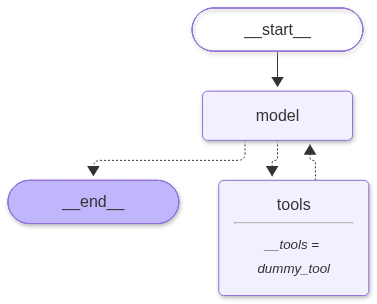

In [27]:
my_agent

In [28]:
response = my_agent.invoke({"messages":[("user", "Hello, I am Prat")]})

In [29]:
response

{'messages': [HumanMessage(content='Hello, I am Prat', additional_kwargs={}, response_metadata={}, id='437508c8-b44b-4403-a9fd-f6f450fb8ceb'),
  AIMessage(content='Hello, Prat! Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hello, I am Prat". Likely they want a greeting. We should respond politely. No tool needed.'}, response_metadata={'token_usage': {'completion_tokens': 54, 'prompt_tokens': 150, 'total_tokens': 204, 'completion_time': 0.113128456, 'completion_tokens_details': {'reasoning_tokens': 28}, 'prompt_time': 0.005653197, 'prompt_tokens_details': None, 'queue_time': 0.280183872, 'total_time': 0.118781653}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_5082008e34', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c6a9-1430-7157-b50f-8b1a6e32d7ba-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 150, 'output_tokens': 54

In [30]:
res_with_tool = my_agent.invoke({"messages":[("user", "Hello, I am Prat. Can you convert 'Ai agent' to uppercase?")]})

In [31]:
res_with_tool

{'messages': [HumanMessage(content="Hello, I am Prat. Can you convert 'Ai agent' to uppercase?", additional_kwargs={}, response_metadata={}, id='303df94f-859c-4518-823c-485b558122ae'),
  AIMessage(content='', additional_kwargs={'reasoning_content': "User wants to convert 'Ai agent' to uppercase. Use dummy_tool.", 'tool_calls': [{'id': 'fc_f9d5e87a-8025-411b-ad05-bd07c895ee77', 'function': {'arguments': '{"inputText":"Ai agent"}', 'name': 'dummy_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 46, 'prompt_tokens': 161, 'total_tokens': 207, 'completion_time': 0.099409788, 'completion_tokens_details': {'reasoning_tokens': 16}, 'prompt_time': 0.006954753, 'prompt_tokens_details': None, 'queue_time': 0.054678035, 'total_time': 0.106364541}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_76082d2bd0', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c6a9-386b-774d-b3b4